# Model comparison — RNN vs. FFNN vs. XGBoost (+ logistic-regression baseline)

All models are scored on the **same official test set** (2 167 events, 150
positive), each at the decision threshold that was frozen on the development set
in its own notebook. This notebook only *plots*: it reads the saved test-set
probabilities and does not retrain the three main models. The logistic
regression baseline is cheap, so it is fitted here with the same protocol as the
FFNN (5 fold models, threshold tuned on out-of-fold F$_2$).

**Figures** (saved as PNG and PDF in `results/comparisons/figures/`):
ROC with AUC, precision–recall with average precision, and confusion matrices.

## 0. What each model notebook must save

Every model notebook ends by writing one file
`results/predictions/<name>.npz` with three arrays. The FFNN notebook already
does this (§10). Paste the matching cell at the end of the RNN and XGBoost
notebooks (change the variable names to whatever holds the test probabilities):

```python
import numpy as np
from pathlib import Path
PRED_DIR = Path("..") / "results" / "predictions"; PRED_DIR.mkdir(parents=True, exist_ok=True)
np.savez(PRED_DIR / "rnn.npz",            # or "xgboost.npz"
         y_true=np.asarray(y_test).astype(int),   # true test labels
         proba=y_test_prob,                        # P(high risk), one per test event
         threshold=THRESHOLD)                      # the frozen decision threshold
```

Models whose file is missing are skipped with a warning, so the notebook runs
with whatever is available.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, confusion_matrix, fbeta_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path.cwd()))
import read_data as rd

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 3155
PRED_DIR = Path("..") / "results" / "predictions"
OUT_DIR = Path("..") / "results" / "comparisons"
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
(OUT_DIR / "tables").mkdir(parents=True, exist_ok=True)

# Paper-sized text: titles and axis labels are deliberately large.
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 14, "axes.titlesize": 20, "axes.titleweight": "bold",
    "axes.labelsize": 17, "xtick.labelsize": 14, "ytick.labelsize": 14,
    "legend.fontsize": 13, "axes.linewidth": 1.2, "lines.linewidth": 2.6,
    "axes.spines.top": False, "axes.spines.right": False,
})

#: display name -> (file stem, colour, marker). Logistic regression is a baseline.
MODELS = {
    "RNN":                 ("rnn",      "#d95f02", "o"),
    "FFNN":                ("ffnn",     "#1b78b4", "s"),
    "XGBoost":             ("xgboost",  "#2ca02c", "^"),
    "Logistic regression": (None,       "#7b3294", "D"),
}
CHANCE_COLOUR = "0.45"
INCLUDE_ALL_NEGATIVE = False     # True: also draw "always predict low risk" in the ROC and confusion plots


def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(OUT_DIR / "figures" / f"{name}.{ext}")
    print(f"  saved {OUT_DIR / 'figures' / name}.png/.pdf")

## 1. Load the saved predictions

In [2]:
preds = {}          # name -> dict(proba, threshold)
y_true = None
for name, (stem, _, _) in MODELS.items():
    if stem is None:
        continue
    f = PRED_DIR / f"{stem}.npz"
    if not f.exists():
        print(f"WARNING: {f} not found -> {name} is skipped")
        continue
    d = np.load(f)
    if y_true is None:
        y_true = d["y_true"].astype(int)
    # Every model must have been scored on the very same events in the same order.
    assert np.array_equal(y_true, d["y_true"].astype(int)), f"{name}: test labels differ"
    preds[name] = dict(proba=np.asarray(d["proba"], dtype=float), threshold=float(d["threshold"]))
    print(f"{name:<10} loaded: {len(d['proba'])} events, threshold = {float(d['threshold']):.4f}")

RNN        loaded: 2167 events, threshold = 0.0100
FFNN       loaded: 2167 events, threshold = 0.6475
XGBoost    loaded: 2167 events, threshold = 0.1900


## 2. Logistic-regression baseline

Same features as the FFNN (per-event aggregates of the shared pipeline, with the
current risk included), class-balanced, and the same protocol as the FFNN: five
fold models on the shared stratified folds, the decision threshold chosen to
maximise F$_2$ on their out-of-fold predictions, and the test probability taken
as the average of the five fold models.

In [3]:
shared = rd.build_shared_datasets(variance_threshold=0.95, include_current_risk=True,
                                  seed=SEED, verbose=False)
agg = shared["aggregate"]
y_dev, y_test_lr = shared["y_class"]["train"], shared["y_class"]["test"].astype(int)

scaler = StandardScaler().fit(agg["train"])
X_dev = scaler.transform(agg["train"])
X_test = scaler.transform(agg["test"])

oof = np.zeros(len(y_dev))
fold_models = []
for fit_idx, val_idx in shared["cv_folds"]:
    m = LogisticRegression(max_iter=5000, class_weight="balanced").fit(X_dev[fit_idx], y_dev[fit_idx])
    oof[val_idx] = m.predict_proba(X_dev[val_idx])[:, 1]
    fold_models.append(m)

cand = np.unique(np.quantile(oof, np.linspace(0, 1, 401)))
f2s = [fbeta_score(y_dev, (oof >= t).astype(int), beta=2, zero_division=0) for t in cand]
thr_lr = float(cand[int(np.argmax(f2s))])
proba_lr = np.mean([m.predict_proba(X_test)[:, 1] for m in fold_models], axis=0)

if y_true is None:
    y_true = y_test_lr
assert np.array_equal(y_true, y_test_lr), "logistic-regression test labels differ from the saved models'"
preds["Logistic regression"] = dict(proba=proba_lr, threshold=thr_lr)
print(f"logistic regression: threshold = {thr_lr:.4f}")
print(f"test set: {len(y_true)} events, {y_true.sum()} positive ({y_true.mean():.1%})")

logistic regression: threshold = 0.2413
test set: 2167 events, 150 positive (6.9%)


## 3. Metrics table

In [4]:
rows = []
for name, d in preds.items():
    pred = (d["proba"] >= d["threshold"]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    rows.append({
        "model": name, "threshold": d["threshold"],
        "ROC-AUC": roc_auc_score(y_true, d["proba"]),
        "PR-AUC (AP)": average_precision_score(y_true, d["proba"]),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "F2": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "TP": tp, "FN": fn, "FP": fp, "TN": tn,
    })
rows.append({"model": "Always low risk", "threshold": np.nan, "ROC-AUC": 0.5,
             "PR-AUC (AP)": y_true.mean(), "precision": 0.0, "recall": 0.0, "F2": 0.0,
             "TP": 0, "FN": int(y_true.sum()), "FP": 0, "TN": int((y_true == 0).sum())})
metrics = pd.DataFrame(rows)
metrics.to_csv(OUT_DIR / "tables" / "test_metrics.csv", index=False)
metrics.round(3)

,model,threshold,ROC-AUC,PR-AUC (AP),precision,recall,F2,TP,FN,FP,TN
0,RNN,0.010,0.789,0.195,0.148,0.820,0.430,123,27,706,1311
1,FFNN,0.648,0.889,0.406,0.457,0.420,0.427,63,87,75,1942
2,XGBoost,0.190,0.942,0.602,0.663,0.420,0.453,63,87,32,1985
3,Logistic regression,0.241,0.913,0.493,0.475,0.507,0.500,76,74,84,1933
4,Always low risk,NaN,0.500,0.069,0.000,0.000,0.000,0,150,0,2017


### Challenge cost (MSE / F$_2$)

The competition's score, as implemented in `read_data.cost`: the mean squared
error of the predicted probabilities divided by F$_2$ at the model's frozen
threshold. **Lower is better**; a model with F$_2$ = 0 scores infinity. The MSE
alone rewards calibrated probabilities, so it is shown next to F$_2$ to see which
factor drives the ranking.


In [5]:
from sklearn.metrics import mean_squared_error

cost_rows = []
for name, d in preds.items():
    pred = (d["proba"] >= d["threshold"]).astype(int)
    mse = mean_squared_error(y_true, d["proba"])
    f2 = fbeta_score(y_true, pred, beta=2, zero_division=0)
    cost_rows.append({"model": name, "threshold": d["threshold"], "MSE": mse, "F2": f2,
                      "cost = MSE / F2": mse / f2 if f2 > 0 else np.inf})
# Untrained operator rule: flag the event if the last pre-cutoff CDM already has
# risk >= -6. It has no probability, so its 0/1 flags stand in for one in the MSE.
rule_flag = (shared["event_meta"]["test"]["last_risk"].values >= rd.HIGH_RISK_THRESHOLD).astype(int)
rule_f2 = fbeta_score(y_true, rule_flag, beta=2, zero_division=0)
rule_mse = mean_squared_error(y_true, rule_flag)
cost_rows.append({"model": "Rule: current risk >= -6", "threshold": rd.HIGH_RISK_THRESHOLD,
                  "MSE": rule_mse, "F2": rule_f2,
                  "cost = MSE / F2": rule_mse / rule_f2 if rule_f2 > 0 else np.inf})
# "Always low risk" predicts probability 0 for every event, so its MSE is the prevalence.
cost_rows.append({"model": "Always low risk", "threshold": np.nan,
                  "MSE": mean_squared_error(y_true, np.zeros(len(y_true))), "F2": 0.0,
                  "cost = MSE / F2": np.inf})
cost_table = pd.DataFrame(cost_rows).sort_values("cost = MSE / F2").reset_index(drop=True)
cost_table.to_csv(OUT_DIR / "tables" / "test_cost.csv", index=False)
cost_table.round(4)


,model,threshold,MSE,F2,cost = MSE / F2
0,Rule: current risk >= -6,-6.0000,0.0452,0.7391,0.0612
1,Logistic regression,0.2413,0.0490,0.5000,0.0980
2,XGBoost,0.1900,0.0480,0.4532,0.1060
3,FFNN,0.6475,0.0984,0.4268,0.2305
4,RNN,0.0100,0.1377,0.4304,0.3200
5,Always low risk,NaN,0.0692,0.0000,inf


## 4. ROC curves with AUC

Marker = each model's operating point at its frozen threshold. A classifier
that outputs the same score for every event (e.g. "always low risk") has a ROC
*curve* equal to the diagonal (AUC = 0.5); as a single *decision* it is the point
(0, 0), drawn as a cross. Accuracy would call it 93 % correct, which is why it is
shown.

  saved ../results/comparisons/figures/roc_comparison.png/.pdf


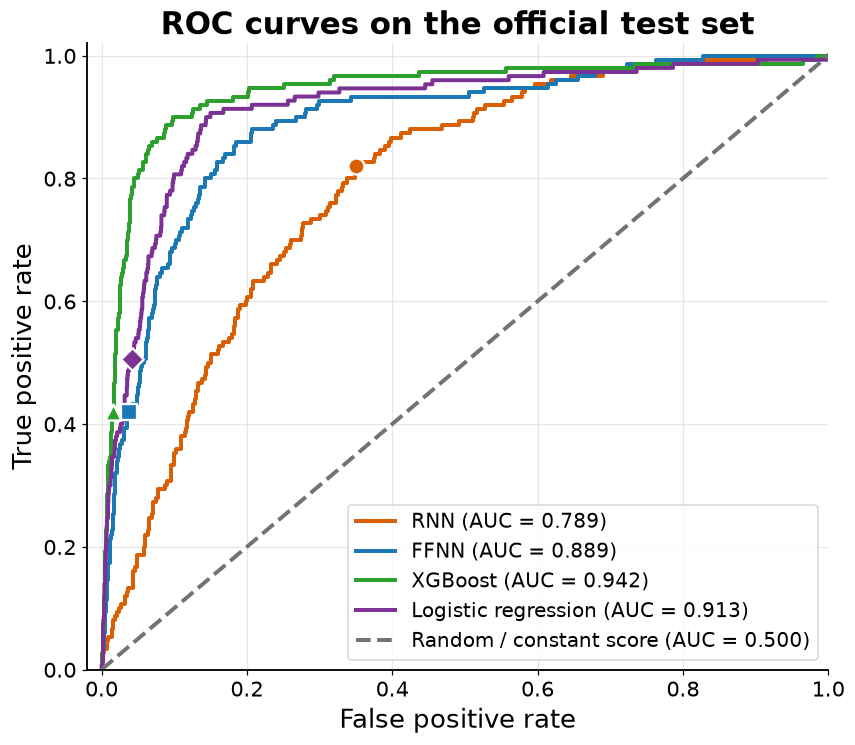

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
for name, d in preds.items():
    _, col, mk = MODELS[name]
    fpr, tpr, _ = roc_curve(y_true, d["proba"])
    ax.plot(fpr, tpr, color=col, label=f"{name} (AUC = {roc_auc_score(y_true, d['proba']):.3f})")
    pred = (d["proba"] >= d["threshold"]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    ax.scatter(fp / (fp + tn), tp / (tp + fn), s=110, color=col, marker=mk,
               edgecolor="white", linewidth=1.5, zorder=5)
ax.plot([0, 1], [0, 1], linestyle="--", color=CHANCE_COLOUR,
        label="Random / constant score (AUC = 0.500)")
if INCLUDE_ALL_NEGATIVE:
    ax.scatter([0], [0], s=170, color="black", marker="X", zorder=6,
               label="Always low risk (single point)")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the official test set")
ax.set_xlim(-0.02, 1.0); ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.tight_layout()
save(fig, "roc_comparison")
plt.show()

## 5. Precision–recall curves with average precision

Markers show the operating points at the frozen thresholds. The dashed line is
the no-skill level (precision = prevalence); it is also the PR curve of any
constant-score classifier. "Always low risk" has recall 0 and an undefined
precision, so it has no point here.

  saved ../results/comparisons/figures/pr_comparison.png/.pdf


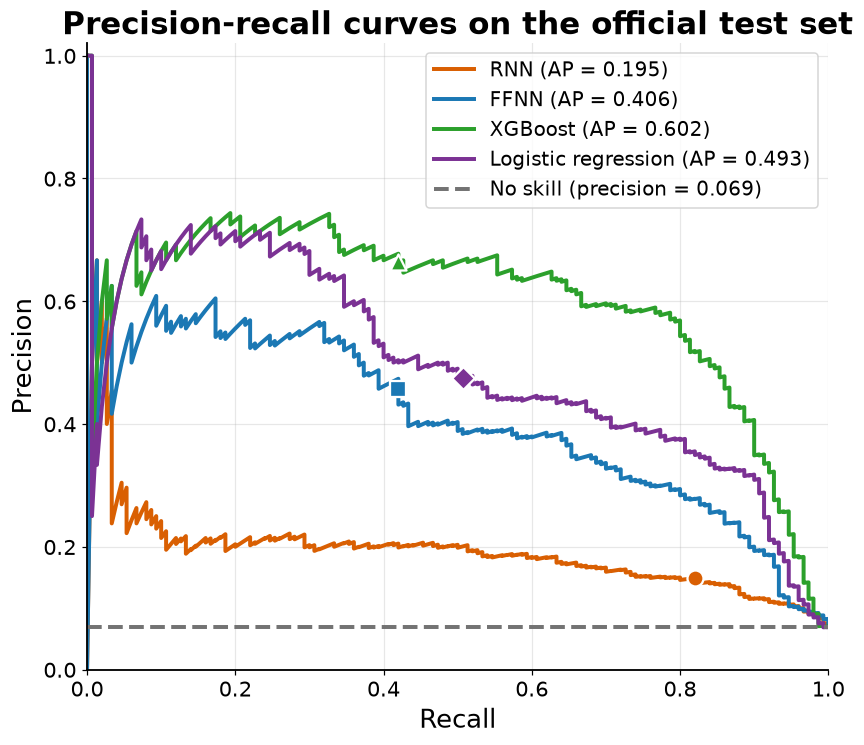

In [7]:
prevalence = y_true.mean()
fig, ax = plt.subplots(figsize=(8, 7))
for name, d in preds.items():
    _, col, mk = MODELS[name]
    prec, rec, _ = precision_recall_curve(y_true, d["proba"])
    ax.plot(rec, prec, color=col,
            label=f"{name} (AP = {average_precision_score(y_true, d['proba']):.3f})")
    pred = (d["proba"] >= d["threshold"]).astype(int)
    ax.scatter(recall_score(y_true, pred, zero_division=0),
               precision_score(y_true, pred, zero_division=0), s=110, color=col,
               marker=mk, edgecolor="white", linewidth=1.5, zorder=5)
ax.axhline(prevalence, linestyle="--", color=CHANCE_COLOUR,
           label=f"No skill (precision = {prevalence:.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall curves on the official test set")
ax.set_xlim(0, 1.0); ax.set_ylim(0, 1.02)
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
fig.tight_layout()
save(fig, "pr_comparison")
plt.show()

## 6. Confusion matrices

One panel per model, at its frozen threshold. Cell shading is the **row-normalised**
fraction (so the 150 positives are not drowned by ~2 000 negatives); the printed
numbers are the raw counts and, in brackets, that row percentage.

  saved ../results/comparisons/figures/confusion_comparison.png/.pdf


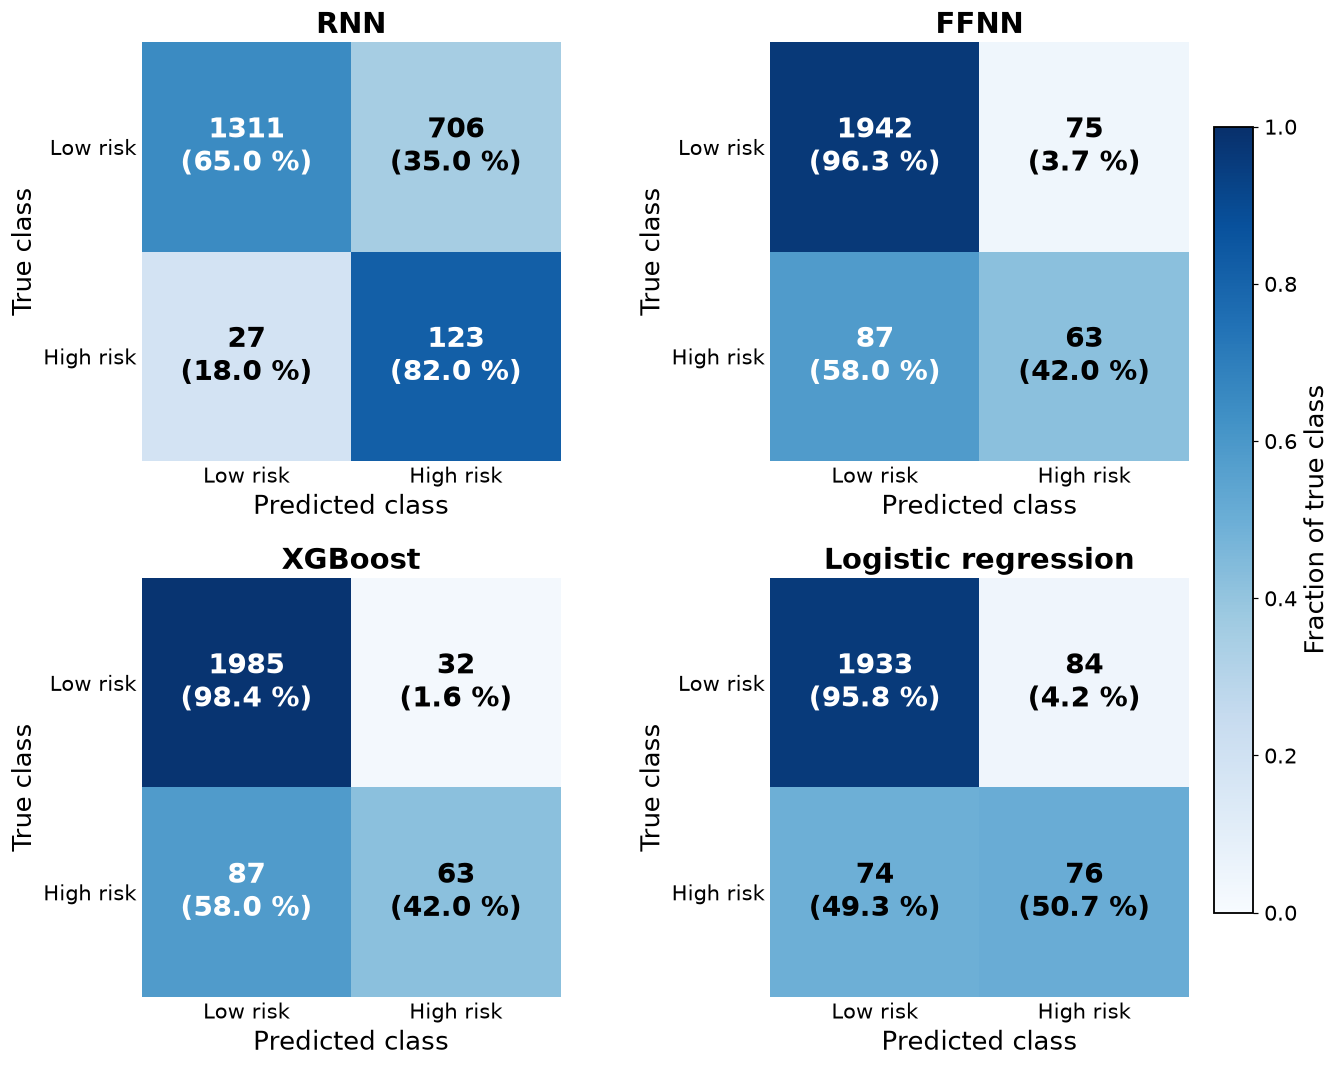

In [8]:
panels = dict(preds)
if INCLUDE_ALL_NEGATIVE:
    panels["Always low risk"] = dict(proba=np.zeros(len(y_true)), threshold=0.5)

ncols = 2
nrows = int(np.ceil(len(panels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(7.4 * ncols, 5.8 * nrows), squeeze=False,
                         gridspec_kw={"wspace": 0.5})
labels = ["Low risk", "High risk"]
for ax, (name, d) in zip(axes.ravel(), panels.items()):
    pred = (d["proba"] >= d["threshold"]).astype(int)
    cm = confusion_matrix(y_true, pred, labels=[0, 1])
    frac = cm / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({100 * frac[i, j]:.1f} %)", ha="center", va="center",
                    fontsize=18, fontweight="bold",
                    color="white" if frac[i, j] > 0.55 else "black")
    ax.set_xticks([0, 1], labels); ax.set_yticks([0, 1], labels)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.set_title(name, fontsize=19)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
for ax in axes.ravel()[len(panels):]:
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8, pad=0.02, label="Fraction of true class")
save(fig, "confusion_comparison")
plt.show()